# Breast Cancer Classification with Machine Learning

A reproducible classification project using the Wisconsin Diagnostic Breast Cancer dataset bundled with Scikit-learn. The notebook explores the data, trains a Logistic Regression model in a preprocessing pipeline, and evaluates held-out predictions.

> **Important:** This is an educational machine-learning project, not a medical device or a substitute for professional diagnosis.

## Objectives
- Explore the dataset and class distribution.
- Prepare a stratified train/test split.
- Standardize features and train Logistic Regression in a pipeline.
- Evaluate results with accuracy, a classification report, and a labeled confusion matrix.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the dataset

In [2]:
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame.copy()

# Scikit-learn encodes malignant as 0 and benign as 1.
class_names = list(cancer.target_names)
print(f"Rows: {df.shape[0]:,}")
print(f"Predictor features: {len(cancer.feature_names)}")
print("Target mapping:", {i: name for i, name in enumerate(class_names)})
df.head()

Rows: 569
Predictor features: 30
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Explore and validate the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


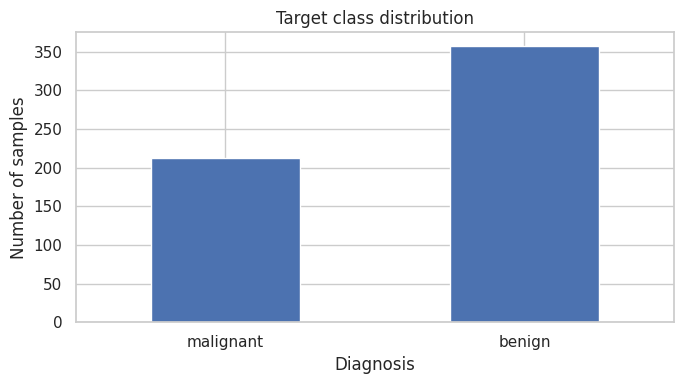

In [5]:
plt.figure(figsize=(7, 4))
class_counts = df["target"].value_counts().reindex([0, 1])
ax = class_counts.plot(kind="bar", rot=0)
ax.set_xticks([0, 1], labels=class_names)
ax.set(title="Target class distribution", xlabel="Diagnosis", ylabel="Number of samples")
plt.tight_layout()
plt.show()

### Feature correlations

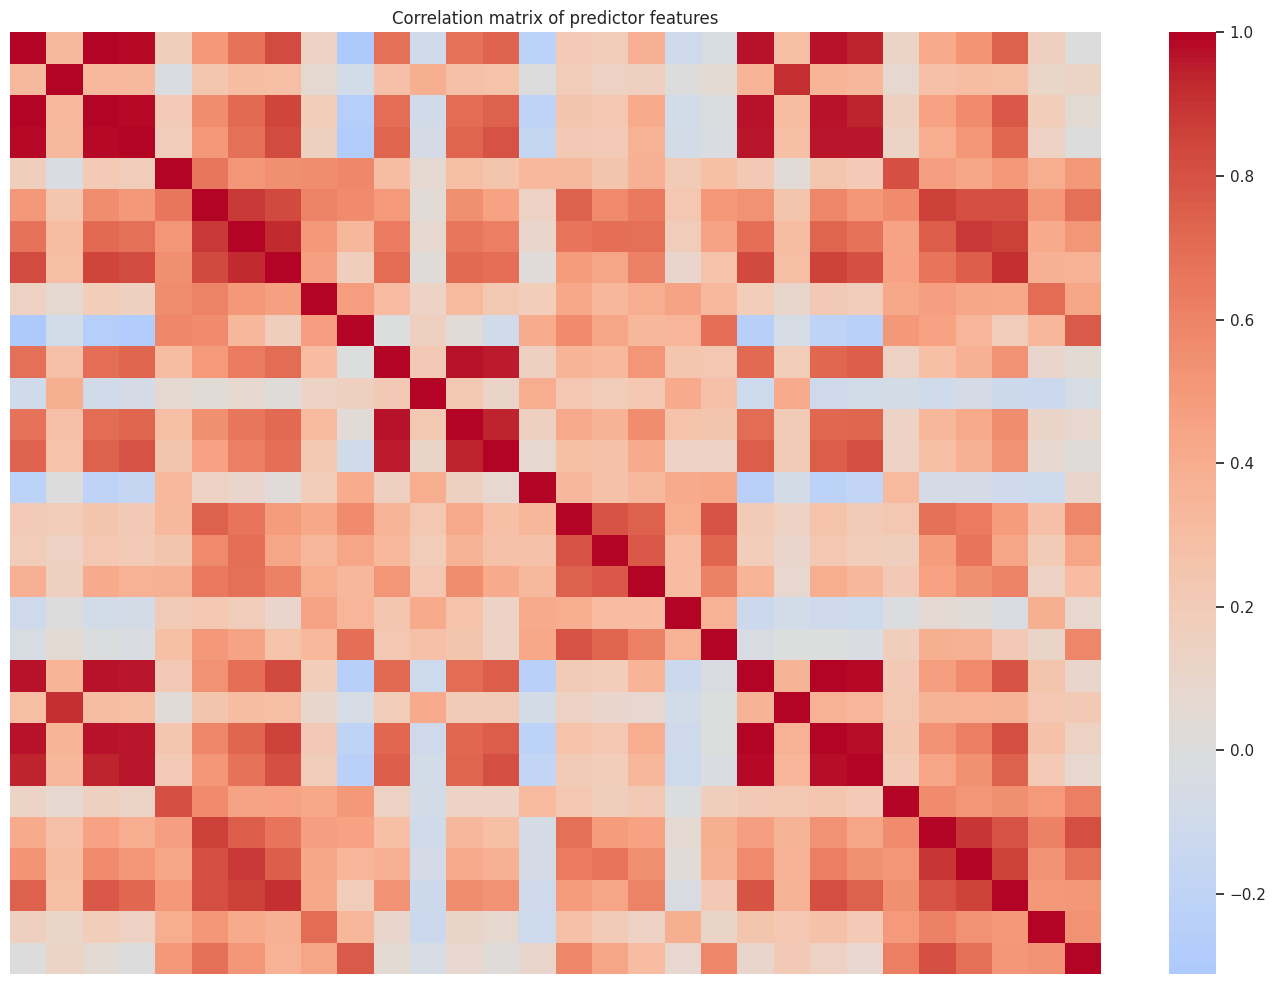

In [6]:
correlation = df.drop(columns="target").corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix of predictor features")
plt.tight_layout()
plt.show()

## 4. Split features and target

In [7]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 426
Test samples: 143


## 5. Train Logistic Regression

In [8]:
# Scaling is fitted only on the training data because it is inside the pipeline.
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model training complete.")

Model training complete.


## 6. Evaluate the model

In [9]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.4f} ({accuracy:.2%})")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4, zero_division=0))

Test accuracy: 0.9860 (98.60%)

Classification report:
              precision    recall  f1-score   support

   malignant     0.9811    0.9811    0.9811        53
      benign     0.9889    0.9889    0.9889        90

    accuracy                         0.9860       143
   macro avg     0.9850    0.9850    0.9850       143
weighted avg     0.9860    0.9860    0.9860       143



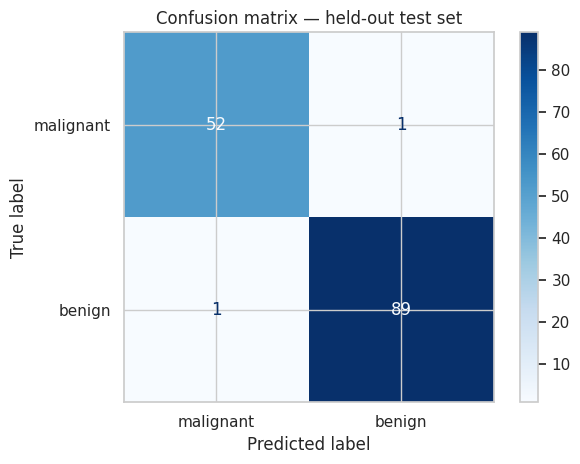

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — held-out test set")
plt.tight_layout()
plt.show()

## 7. Interpretation and limitations

- **Accuracy** is the fraction of test examples classified correctly; it should not be interpreted in isolation.
- **Precision** describes how often predictions for a class are correct.
- **Recall** describes how many actual examples of a class the model identifies.
- **F1-score** balances precision and recall.
- **Support** is the number of true examples of each class in the test set.

The confusion matrix uses the label order **malignant, benign**. In a medical context, false negatives and false positives have different implications, so class-specific precision and recall matter. The dataset is a benchmark dataset and the test set is small; these results do not establish clinical safety, generalization to other populations, or diagnostic performance in practice.

## 8. Reproducibility

The dataset is loaded directly from Scikit-learn, so no separate dataset download is required. A fixed random seed makes the split reproducible. The scaler is fitted on the training data only to avoid leakage from the test set.